# Frequency-search results explorer

Look at the output of an adversarial frequency search (`freq_search.py`): the
per-`(letter, pattern)` multipliers, the resulting per-word frequencies, and the
greedy strategy analyzed the *same way* as in `strategy_explorer` but under the
adversarial weighting (greedy playing against the adversarial word choices).

Generate a run first with e.g. `python math/freq_search.py 5` (saves to
`math/data/freq_search/len05.csv`); this notebook loads it back.

In [1]:
from pathlib import Path
import sys

def find_math_dir():
    cwd = Path.cwd().resolve()
    for c in (cwd, cwd.parent, cwd.parent.parent, cwd / 'math', cwd.parent / 'math'):
        if (c / 'freq_search.py').exists():
            return c
    raise FileNotFoundError('Could not find freq_search.py. Open from the repo root, math/, or math/notebooks/.')

math_dir = find_math_dir()
if str(math_dir) not in sys.path:
    sys.path.insert(0, str(math_dir))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import freq_search, strategy

print(f'imported from {math_dir}')

imported from /Users/patrickliscio/My Documents/Pycharm Projects/Ballpark-Figures/hangman/math


## Load a search result

Loads the saved CSV for this length if present; otherwise runs one inline (which
can be slow for larger lengths).

In [29]:
LENGTH = 4

csv_path = math_dir / 'data' / 'freq_search' / f'len{LENGTH:02d}.csv'
if csv_path.exists():
    s = freq_search.FrequencySearch.reconstruct(LENGTH, csv_path)
    print(f'loaded saved run: {csv_path.name}')
else:
    print(f'no saved run at {csv_path}\nrunning one inline (may take a while)...')
    s = freq_search.FrequencySearch(LENGTH)
    s.run(verbose=False)

game, f = s.game, s.freq
print(f'length {LENGTH}: {game.N} words, {s.M} patterns')
print(f'greedy avg misses -- uniform: {game.average_misses():.4f}   '
      f'adversarial: {game.average_misses(f):.4f}')

loaded saved run: len04.csv
length 4: 2120 words, 167 patterns
greedy avg misses -- uniform: 5.4778   adversarial: 6.9062


## Multipliers

One row per `(letter, pattern)`; `multiplier` is the tuned weight, `n_words` how
many words carry that pattern.

In [30]:
mult_df = s.multipliers_df()
print(f'{(mult_df.multiplier == 0).sum()} patterns zeroed; '
      f'{(mult_df.multiplier > 1).sum()} boosted above 1; '
      f'max multiplier {mult_df.multiplier.max():g}')
mult_df.head(20)

51 patterns zeroed; 34 boosted above 1; max multiplier 11.375


,letter,pattern,mask,multiplier,n_words
0,v,___v,8,11.375,3
1,z,___z,8,7.500,3
2,j,__jj,12,6.500,1
3,z,__zz,12,6.125,4
4,t,__tt,12,4.750,4
5,f,f_f_,5,4.625,1
6,x,__x_,4,4.500,9
7,f,__ff,12,4.000,12
8,b,b_b_,5,4.000,3
9,m,_m_m,10,4.000,1


In [31]:
mult_df.tail(20)

,letter,pattern,mask,multiplier,n_words
147,t,_t__,2,0.0,18
148,p,_p__,2,0.0,23
149,u,___u,8,0.0,7
150,h,_h__,2,0.0,66
151,d,_dd_,6,0.0,3
152,i,_i_i,10,0.0,4
153,g,g__g,9,0.0,3
154,g,_g__,2,0.0,7
155,o,_o_o,10,0.0,10
156,c,_c__,2,0.0,20


## Frequencies

One row per word (frequency = product of its pattern multipliers).

In [32]:
freq_df = s.frequencies_df()
print(f'{(freq_df.frequency == 0).sum()} words at frequency 0 (removed); '
      f'heaviest carry the adversarial weight:')
freq_df.head(15)

840 words at frequency 0 (removed); heaviest carry the adversarial weight:


,word,frequency
0,jeez,15.000
1,hajj,13.000
2,jazz,12.250
3,buzz,12.250
4,fizz,12.250
5,fuzz,12.250
6,perv,11.375
7,noon,10.500
8,putt,9.500
9,watt,9.500


## Greedy: uniform vs adversarial

Each cell below runs the same analysis **both ways** — `uniform` (`freq=None`, the
`strategy_explorer` baseline) and `adversarial` (`freq=s.freq`, playing against
the tuned word distribution). The only difference is which `freq` you pass to the
`game` methods.

     uniform:  avg misses 5.4778   opener 'e'
 adversarial:  avg misses 6.9062   opener 'a'


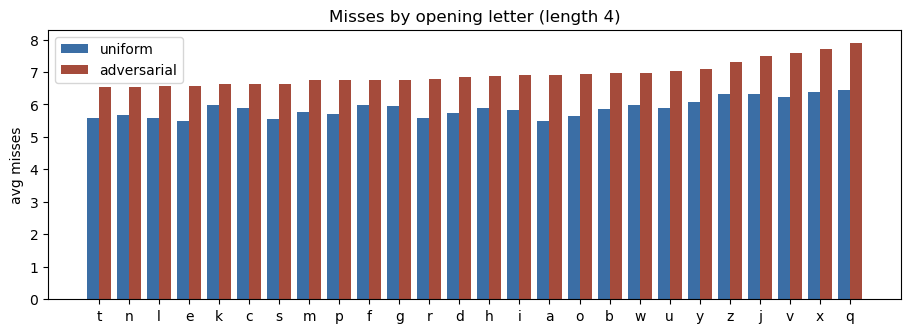

,t,n,l,e,k,c,s,m,p,f,...,o,b,w,u,y,z,j,v,x,q
uniform,5.570755,5.673585,5.579245,5.47783,5.998585,5.880660,5.553774,5.771226,5.718868,5.970283,...,5.630660,5.863208,5.976415,5.897170,6.085377,6.332547,6.334906,6.228774,6.384434,6.449528
adversarial,6.544146,6.548936,6.569446,6.57626,6.634302,6.639721,6.645345,6.743126,6.748282,6.768758,...,6.952819,6.969133,6.981400,7.025563,7.102971,7.293892,7.505745,7.581164,7.712568,7.906243


In [33]:
# avg misses + opening letter, each version
for name, fr in [('uniform', None), ('adversarial', f)]:
    print(f'{name:>12}:  avg misses {game.average_misses(fr):.4f}   '
          f'opener {game.greedy_first_letter(fr)!r}')

# Mode B -- expected misses by opening letter, both versions side by side
mb = pd.DataFrame({
    'uniform':     pd.Series(game.misses_by_starting_letter(None)),
    'adversarial': pd.Series(game.misses_by_starting_letter(f)),
}).sort_values('adversarial')

x = np.arange(len(mb)); w = 0.4
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.bar(x - w / 2, mb['uniform'],     w, label='uniform',     color='#3b6ea5')
ax.bar(x + w / 2, mb['adversarial'], w, label='adversarial', color='#a54b3b')
ax.set_xticks(x); ax.set_xticklabels(mb.index)
ax.set_ylabel('avg misses'); ax.legend()
ax.set_title(f'Misses by opening letter (length {LENGTH})')
plt.show()
mb.T

## Per-word difficulty (both versions)

weighted avg misses -- uniform 5.4778   adversarial 6.9062


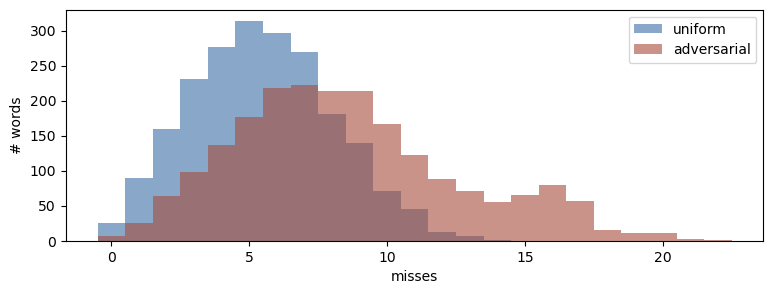

hardest words under the adversarial distribution:


,word,freq,misses_uniform,misses_adversarial
0,eyes,0.0,2,22
1,says,0.0,5,21
2,exes,0.0,1,21
3,flex,0.0,7,20
4,clay,0.0,8,20
5,whew,0.0,4,20
6,axed,0.0,5,20
7,flax,0.0,9,20
8,whey,0.0,5,20
9,year,0.0,10,20


In [34]:
pwm_u = game.per_word_misses(None)      # uniform
pwm_a = game.per_word_misses(f)         # adversarial
words = pd.DataFrame({'word': game.words, 'freq': f,
                      'misses_uniform':     pwm_u.astype(int),
                      'misses_adversarial': pwm_a.astype(int)})

print(f'weighted avg misses -- uniform {game.average_misses(None):.4f}   '
      f'adversarial {game.average_misses(f):.4f}')

bins = range(0, int(max(pwm_u.max(), pwm_a.max())) + 2)
fig, ax = plt.subplots(figsize=(9, 3))
ax.hist(pwm_u, bins=bins, alpha=0.6, label='uniform',     color='#3b6ea5', align='left')
ax.hist(pwm_a, bins=bins, alpha=0.6, label='adversarial', color='#a54b3b', align='left')
ax.set_xlabel('misses'); ax.set_ylabel('# words'); ax.legend()
plt.show()

print('hardest words under the adversarial distribution:')
words.sort_values('misses_adversarial', ascending=False).head(15).reset_index(drop=True)

In [ ]:
# The adversary zeros out many words (freq 0) -- those don't count toward its
# average. Hardest words it actually KEEPS (nonzero adversarial frequency):
kept = words[words.freq > 0]
print(f'{len(kept)} of {len(words)} words kept (nonzero frequency)')
kept.sort_values('misses_adversarial', ascending=False).head(15).reset_index(drop=True)

## Trace a word (both versions)

The greedy guess sequence for one word under each weighting (`+` = hit, `-` = miss).
The two can differ because the adversarial weighting changes which letters greedy
guesses first.

In [ ]:
# hardest word the adversary actually KEEPS (nonzero frequency); or set WORD = 'bench'
nz = np.flatnonzero(f > 0)
WORD = game.words[nz[pwm_a[nz].argmax()]]
print(WORD)
for name, fr in [('uniform', None), ('adversarial', f)]:
    hits = game.trace(WORD, fr)
    seq = '  '.join(f'{l}{"+" if h else "-"}' for l, h in hits)
    print(f'{name:>12}  ({sum(1 for _, h in hits if not h)} misses):  {seq}')